# Conecta+ · ¿A quién contactar y por qué se van?

In [1]:
import os, sys, subprocess, zipfile
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/unfresh25/conecta-churn.git"

if IN_COLAB:
    if not Path("/content/repo/conecta").exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, "/content/repo"], check=True)
    os.chdir("/content/repo")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
    # Opción A: zip subido a /content. Opción B: descomentar para leerlo desde Drive.
    ZIP_PATH = Path("/content/datos_conecta.zip")
    # from google.colab import drive; drive.mount("/content/drive")
    # ZIP_PATH = Path("/content/drive/MyDrive/<ruta>/datos_conecta.zip")
else:
    ZIP_PATH = Path("datos_conecta.zip")

DATA_DIR = Path("datos")
if not (DATA_DIR / "conecta.db").exists():
    assert ZIP_PATH.exists(), f"No encuentro {ZIP_PATH}: sube datos_conecta.zip al entorno."
    zipfile.ZipFile(ZIP_PATH).extractall(DATA_DIR)
sys.path.insert(0, str(Path.cwd()))
print("Colab:", IN_COLAB, "| datos:", sorted(p.name for p in DATA_DIR.iterdir()))

Colab: True | datos: ['conecta.db', 'eventos.jsonl.gz', 'tickets.jsonl']


In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
SEED = 42
TODAY = pd.Timestamp("2025-12-31")

## 1. Datos y calidad

Los datos vienen de tres sistemas: la base relacional (`conecta.db`, con clientes, suscripciones, facturas, etiquetas y clientes a
puntuar), la plataforma de atención (`tickets.jsonl`) y los logs de la app (`eventos.jsonl.gz`, solo 2025). No hay diccionario de
datos, así que cada supuesto sobre un campo queda escrito aquí.

In [3]:
from conecta.data import load_data, clean

raw = load_data(DATA_DIR)
data = clean(raw)
pd.DataFrame({
    "tabla": ["clientes", "suscripciones", "facturas", "etiquetas_entrenamiento", "clientes_a_puntuar", "tickets (registros)", "eventos"],
    "filas": [len(raw.clients), len(raw.subscriptions), len(raw.invoices), len(raw.labels), len(raw.to_score), len(raw.tickets_raw), len(raw.events)],
})

,tabla,filas
0,clientes,3000
1,suscripciones,3361
2,facturas,34138
3,etiquetas_entrenamiento,4693
4,clientes_a_puntuar,1556
5,tickets (registros),4452
6,eventos,103927


In [4]:
reloads = len(raw.invoices) - raw.invoices["factura_id"].nunique()
quality = pd.DataFrame([
    ("ciudad: grafías distintas -> ciudades canónicas", f"{raw.clients['ciudad'].nunique()} -> {data.clients['ciudad'].nunique()}"),
    ("ciudad sin mapear (NaN)", int(data.clients["ciudad"].isna().sum())),
    ("edad inválida (0 o 999) -> NaN", int(data.clients["edad"].isna().sum())),
    ("facturas recargadas (mismo factura_id) eliminadas", reloads),
    ("cobros dobles reales (id distinto, mismo periodo) marcados", int(data.invoices["is_duplicate_charge"].sum())),
    ("facturas sin fecha_pago (impagas a hoy)", int(data.invoices["fecha_pago"].isna().sum())),
    ("eventos duplicados (event_id) eliminados", len(raw.events) - len(data.events)),
], columns=["problema", "valor"])
quality

,problema,valor
0,ciudad: grafías distintas -> ciudades canónicas,17 -> 6
1,ciudad sin mapear (NaN),0
2,edad inválida (0 o 999) -> NaN,65
3,facturas recargadas (mismo factura_id) eliminadas,677
4,"cobros dobles reales (id distinto, mismo perio...",699
5,facturas sin fecha_pago (impagas a hoy),1447
6,eventos duplicados (event_id) eliminados,1616


In [5]:
assert set(data.clients["ciudad"].dropna()) == {"Bogotá", "Medellín", "Cali", "Barranquilla", "Bucaramanga", "Pereira"}
assert data.clients["ciudad"].isna().sum() == 0
assert data.clients["edad"].isna().sum() == 65
assert reloads == 677 and data.invoices["is_duplicate_charge"].sum() == 699
assert len(raw.events) - len(data.events) == 1616
print("Controles de calidad OK")

Controles de calidad OK


Supuestos sobre los campos:

- `estado_actual` describe al cliente al 31-dic-2025, no en cada corte. Ningún cliente "activo" aparece como churn en las etiquetas,
  así que usarlo filtraría el resultado. No entra como variable.
- `fecha_contacto_retencion`: el 90 % de los contactos de clientes etiquetados ocurrió después del corte. Solo cuentan los contactos
  con fecha anterior o igual al corte.
- `fecha_carga` es el día en que la factura entró al sistema, de 1 a 4 días después de empezar el periodo. Para el modelo, una factura
  existe solo si se cargó antes del corte.
- Un `factura_id` repetido es una recarga del sistema: la misma factura con otra `fecha_carga`. Dos ids distintos para el mismo
  cliente, periodo y suscripción son un cobro doble real (sección 8).
- `fecha_pago` vacía significa no pagada a hoy. En un corte pasado, una factura pagada después del corte cuenta como impaga.
- `motivo_cancelacion = cambio_plan` cierra una suscripción y abre otra el mismo día, así que no es churn.

### 1.1 Tickets: dos esquemas en un mismo archivo

`tickets.jsonl` mezcla dos formatos. El A (2023-2025) trae `customer: "CL-012375"`, fechas en UTC, `category` y `text`. El B (2025)
anida el cliente (`cliente.id`), usa fechas con zona `-05:00`, tiene un `tipo` con categoría y subcategoría y guarda la conversación
en `mensajes`, donde escriben el cliente y el agente.

Los dos quedan en un solo esquema: `cliente_id` entero, fechas en UTC-5, `status` abierto o cerrado, y como `text` el primer
mensaje del cliente. Los mensajes del agente son tres frases fijas y no dicen nada del cliente.

In [6]:
from conecta.tickets import unify_tickets

data.tickets, dropped = unify_tickets(data.tickets_raw)
print(f"{len(data.tickets_raw)} registros -> {len(data.tickets)} tickets | descartados (cliente o fecha ilegible): {dropped}")
print("por esquema:", data.tickets["schema"].value_counts().to_dict())
print("textos únicos de cliente:", data.tickets["text"].nunique())
assert data.tickets["schema"].value_counts().to_dict() == {"A": 2553, "B": 1899} and dropped == 0

4452 registros -> 4452 tickets | descartados (cliente o fecha ilegible): 0
por esquema: {'A': 2553, 'B': 1899}
textos únicos de cliente: 38


## 2. Etiquetas: más cortes con la misma definición

`etiquetas_entrenamiento` trae tres cortes (marzo, junio y septiembre de 2025): 4.693 filas y 652 cancelaciones. Con eso queda un
solo corte para validar. La etiqueta, en cambio, se puede reconstruir desde `suscripciones`:

- un cliente está activo en la fecha *d* si tiene una suscripción con `fecha_inicio ≤ d` y `fecha_fin` vacía o posterior a *d*;
- `churn_90d = 1` si estaba activo en el corte y 90 días después no tiene ninguna suscripción activa.

Si la regla reproduce las etiquetas entregadas, se puede aplicar a cualquier fin de mes sin inventar una definición propia.

In [7]:
from conecta.labels import active_at, build_labels, monthly_cutoffs

official = data.labels.rename(columns={"fecha_corte": "cutoff", "churn_90d": "churn_official"})
mine = build_labels(data.subscriptions, sorted(official["cutoff"].unique()))
check = official.merge(mine, on=["cliente_id", "cutoff"], how="outer", indicator=True)
summary = check.groupby("cutoff").agg(
    filas_oficiales=("churn_official", "count"), filas_reconstruidas=("churn_90d", "count"),
    coincidencia=("churn_90d", lambda s: (s == check.loc[s.index, "churn_official"]).mean()),
)
summary

,filas_oficiales,filas_reconstruidas,coincidencia
cutoff,,,
2025-03-31,1387,1387,1.0
2025-06-30,1572,1572,1.0
2025-09-30,1734,1734,1.0


In [8]:
assert (check["_merge"] == "both").all()
assert (check["churn_90d"] == check["churn_official"]).all()
assert active_at(data.subscriptions, TODAY) == set(data.to_score["cliente_id"])
print("Etiquetas reconstruidas = etiquetas oficiales (100 %) | activos al 31-dic = clientes_a_puntuar")

Etiquetas reconstruidas = etiquetas oficiales (100 %) | activos al 31-dic = clientes_a_puntuar


Panel de entrenamiento: cortes de fin de mes de enero a septiembre de 2025. El 30-sep es el último corte cuya ventana de 90 días
cierra antes del 31-dic. Se arma también un panel desde marzo de 2023 con las mismas reglas (sección 5); antes de 2025 no hay logs
de la app y esas variables quedan vacías.

In [9]:
TRAIN_CUTOFFS = monthly_cutoffs("2025-01-31", "2025-09-30")
labels = build_labels(data.subscriptions, TRAIN_CUTOFFS)
by_cutoff = labels.groupby("cutoff")["churn_90d"].agg(clientes="size", churn="sum", tasa="mean")
display(by_cutoff.style.format({"tasa": "{:.1%}"}))
print(f"Panel 2025: {len(labels):,} filas, {labels['churn_90d'].sum():,} cancelaciones, "
      f"{labels['cliente_id'].nunique():,} clientes distintos")
assert len(labels) == 13600 and labels["churn_90d"].sum() == 1815

,clientes,churn,tasa
cutoff,,,
2025-01-31 00:00:00,1293,149,11.5%
2025-02-28 00:00:00,1332,151,11.3%
2025-03-31 00:00:00,1387,158,11.4%
2025-04-30 00:00:00,1439,158,11.0%
2025-05-31 00:00:00,1502,166,11.1%
2025-06-30 00:00:00,1572,211,13.4%
2025-07-31 00:00:00,1626,239,14.7%
2025-08-31 00:00:00,1715,300,17.5%
2025-09-30 00:00:00,1734,283,16.3%


Panel 2025: 13,600 filas, 1,815 cancelaciones, 2,253 clientes distintos


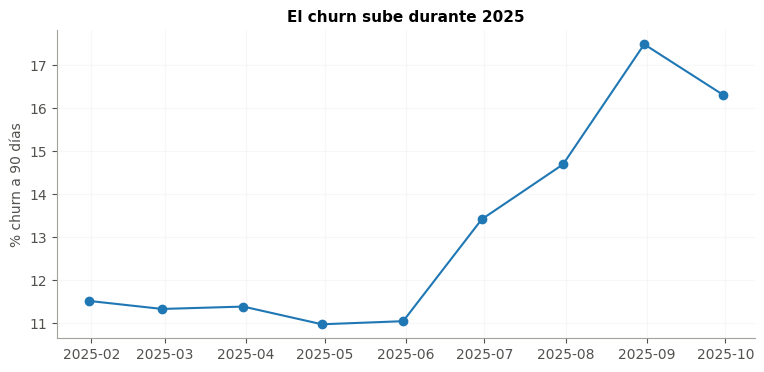

In [43]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(by_cutoff.index, by_cutoff["tasa"] * 100, marker="o")
ax.set_ylabel("% churn a 90 días"); ax.set_title("El churn sube durante 2025"); ax.grid(alpha=.3)
plt.show()

El churn sube de ~11 % a ~17 % durante 2025. Por eso la validación es temporal: se entrena con el pasado y se evalúa en cortes
posteriores, como pasará en enero de 2026. También obliga a revisar la calibración, porque un modelo que no vio el verano puede
subestimar el riesgo actual (sección 5).

## 3. Texto de tickets: qué dice el cliente y en qué tono

Los 4.452 tickets usan solo 38 textos distintos, y cerca de un tercio son sarcásticos, como felicitar a la empresa por una versión
de la app que se cierra sola. De cada texto saco el tema, si el cliente amenaza con irse y si está molesto, sea con enojo directo
o con ironía.

Probé varios enfoques contra una referencia que etiqueté a mano con los 38 textos (detalle en `BITACORA_IA.md`):

| Enfoque | Resultado | ¿Se usa? |
|---|---|---|
| strands-decider (modelo de decisión de 2B, local): tema entre 8 opciones | 38/38 | Sí |
| strands-decider: ¿amenaza con irse? | 37/38 | Sí |
| strands-decider: sarcasmo o "¿está molesto?" (3 redacciones) | detecta de 1 a 3 de 10 sarcásticos | No |
| pysentimiento (modelos en español): ironía | ordena sin errores (AUC 1,0); con corte 0,5 detecta 5 de 10, sin falsos positivos | Sí |
| pysentimiento: emoción "ira" | detecta 8 de 9 enojos directos | Sí |
| pysentimiento: sentimiento negativo | AUC 0,49, porque el sarcasmo sale "positivo" | No |
| TF-IDF o NLP clásico | con 38 textos únicos sería una tabla de búsqueda, y el csat sigue al tema y no al tono, así que tampoco sirve como etiqueta débil | No |

Regla: molesto si hay ira o si la ironía supera 0,5. El 0,5 es el corte natural del modelo. Con un corte de ~0,1 detectaría 17 de 18
molestos, pero ese corte saldría de mirar los mismos 38 textos con los que se evalúa.

Límites: la referencia es chica (38 textos, 10 sarcásticos) y es un juicio mío; las probabilidades de ironía están poco graduadas;
strands-decider es una librería experimental. En producción, un texto nuevo se clasificaría al llegar y, si la confianza es baja,
pasaría a revisión humana.

La clasificación se calcula una vez y se guarda en `data_derivada/tickets_clasificados.csv`, indexada por un hash del texto para no
publicar textos de clientes. Con `RECALCULATE_NLP = True` se regenera en Colab: instala strands-decider y pysentimiento, levanta el
servidor del modelo y tarda unos minutos.

In [11]:
from conecta.tickets import DECIDER_MODEL, classify_texts, hash_text, load_classification

RECALCULATE_NLP = False
MAX_WAIT_SECONDS = 900
CLASSIFICATION_PATH = Path("data_derivada/tickets_clasificados.csv")

if RECALCULATE_NLP:
    import time, urllib.request
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "strands-decider", "pysentimiento"], check=True)
    server = subprocess.Popen(["strands-decider", "serve", DECIDER_MODEL, "--port", "8765"],
                              stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    for _ in range(MAX_WAIT_SECONDS // 5):
        try:
            urllib.request.urlopen("http://127.0.0.1:8765/health", timeout=5); break
        except Exception:
            time.sleep(5)
    try:
        classify_texts(data.tickets["text"].dropna().unique().tolist()).to_csv(CLASSIFICATION_PATH, index=False)
    finally:
        server.terminate()

classification = load_classification(CLASSIFICATION_PATH)
data.tickets["hash"] = data.tickets["text"].map(hash_text, na_action="ignore")
coverage = data.tickets["hash"].isin(classification["hash"]).mean()
print(f"Textos clasificados: {len(classification)} | tickets cubiertos por la clasificación: {coverage:.1%}")

Textos clasificados: 38 | tickets cubiertos por la clasificación: 100.0%


In [12]:
tk = data.tickets.merge(classification, on="hash", how="left")
pd.crosstab(tk["source_topic"], tk["topic"])

topic,acceso_cuenta,app_se_cierra,aumento_precio,cambio_plan,cancelar,cobro_doble,cobro_no_reconocido,lentitud
source_topic,,,,,,,,
app_se_cierra,0,816,0,0,0,0,0,0
cambio_clave,640,0,0,0,0,0,0,0
cambio_plan,0,0,0,328,0,0,0,0
cancelar,0,0,0,0,722,0,0,0
cobro_doble,0,0,0,0,0,699,0,0
lentitud,0,0,0,0,0,0,0,876
no_reconoce_cobro,0,0,175,0,0,0,196,0


El tema del modelo coincide con la categoría de la plataforma en todos los casos menos uno. La plataforma registra como
`no_reconoce_cobro` dos quejas distintas, y casi la mitad son por un aumento de precio sin aviso. Ese motivo solo se ve en el texto.

In [13]:
summary = tk.groupby("topic").agg(tickets=("ticket_id", "size"), amenaza=("p_threat", lambda s: (s > .5).mean()),
                                  molesto=("annoyed", "mean"), csat=("csat", "mean"))
summary.sort_values("tickets", ascending=False).style.format({"amenaza": "{:.0%}", "molesto": "{:.0%}", "csat": "{:.2f}"})

,tickets,amenaza,molesto,csat
topic,,,,
lentitud,876,0%,29%,3.36
app_se_cierra,816,18%,56%,2.48
cancelar,722,100%,17%,3.72
cobro_doble,699,12%,60%,2.79
acceso_cuenta,640,0%,0%,3.31
cambio_plan,328,33%,0%,3.42
cobro_no_reconocido,196,0%,0%,3.40
aumento_precio,175,0%,100%,3.46


## 4. Variables: qué sabía la empresa de cada cliente en la fecha de corte

Cada variable usa solo lo que se sabía en el corte. Las funciones están en `conecta/features.py`. `tests/test_features.py` prueba las
reglas de contactos, tickets resueltos y csat posteriores al corte, el borde de zona horaria de los tickets y los cobros dobles.

| Bloque | Variables | Regla contra fugas |
|---|---|---|
| Cliente | antigüedad, segmento, ciudad, edad (con indicador de edad inválida), canal, plataforma | `estado_actual` no se usa |
| Suscripción | plan vigente, días en el plan, suscripciones previas, cambios de plan | solo suscripciones iniciadas antes del corte |
| Facturación | pagos tarde (90 y 180 días), vencidas sin pagar, cobros dobles (total y 90 días), mensualidad, débito automático, afectado por el aumento del Básico | solo facturas cargadas antes del corte; un pago posterior al corte cuenta como impago |
| Uso de la app | logins de 30 y 90 días y su tendencia, eventos, errores, tasa de errores, cierres al abrir, funcionalidades usadas, usa la 5.2.0, días desde el último uso | fecha local ≤ corte |
| Tickets | tickets de 30 y 90 días, por tema, molestos, amenazas, abiertos, csat promedio, días desde el último | el csat cuenta solo si el ticket ya estaba resuelto |
| Retención | contactado antes, días desde el contacto | solo contactos con fecha ≤ corte |

Un cliente sin eventos o sin tickets queda con conteos en 0 y un indicador (`no_events`, `no_tickets`); no se descarta. Los logs
empiezan el 1-ene-2025, así que en los cortes de enero y febrero la ventana de 90 días está incompleta.

In [14]:
from conecta.features import build_matrix, build_panel

panel = build_panel(data, classification, labels)
score_ids = pd.Index(data.to_score["cliente_id"], name="cliente_id")
X_score = build_matrix(data, classification, TODAY, score_ids)
print(f"Panel de entrenamiento: {panel.shape} | matriz a puntuar (31-dic-2025): {X_score.shape}")
assert len(panel) == 13600 and len(X_score) == 1556 and X_score["plan"].notna().all()
nulls = panel.isna().mean()
nulls[nulls > 0].sort_values(ascending=False).to_frame("% nulos").style.format("{:.1%}")

Panel de entrenamiento: (13600, 54) | matriz a puntuar (31-dic-2025): (1556, 51)


,% nulos
days_since_contact,98.5%
csat_mean,50.6%
days_since_last_ticket,47.5%
error_rate_90d,2.6%
days_since_last_event,2.6%
age,2.3%


In [15]:
looks = {
    "ticket 'cancelar' (90 días)": panel["topic_cancelar_90d"] > 0,
    "usa la app 5.2.0": panel["uses_v520"] == 1,
    "cobro doble (90 días)": panel["duplicate_charges_90d"] > 0,
    "ticket molesto (90 días)": panel["annoyed_90d"] > 0,
    "factura vencida sin pagar": panel["overdue_unpaid"] > 0,
    "sin uso de la app": panel["no_events"] == 1,
}
pd.DataFrame({k: {"filas": int(m.sum()), "churn si": panel.loc[m, "churn_90d"].mean(), "churn no": panel.loc[~m, "churn_90d"].mean()}
              for k, m in looks.items()}).T.style.format({"churn si": "{:.1%}", "churn no": "{:.1%}", "filas": "{:,.0f}"})

,filas,churn si,churn no
ticket 'cancelar' (90 días),66,100.0%,12.9%
usa la app 5.2.0,595,28.2%,12.7%
cobro doble (90 días),692,20.2%,13.0%
ticket molesto (90 días),974,17.2%,13.0%
factura vencida sin pagar,"4,302",15.6%,12.3%
sin uso de la app,349,29.5%,12.9%


Un ticket de "cancelar" en los últimos 90 días equivale a churn: 100 % en el panel. La señal es legítima, porque el ticket es anterior
al corte, pero es casi la cancelación misma. Queda la pregunta de si llamar a ese cliente rinde el 40 % que supone el enunciado; la
sección 6 la responde.

## 5. Modelos: validación temporal y corridas en MLflow

Simulo lo que habría pasado si el modelo se hubiera usado en julio, agosto y septiembre de 2025. Para evaluar en el corte E entreno
solo con cortes C ≤ E − 3 meses. La etiqueta de C se conoce en C + 90 días, así que toda etiqueta de entrenamiento ya existía el día E
(`conecta/validation.py`). No uso validación cruzada aleatoria: un mismo cliente aparece en varios cortes y el churn cambia en el
tiempo, así que mezclar filas al azar promete un desempeño que en producción no se tendría.

Mido el orden con AUC-PR y AUC, la calidad de la probabilidad con Brier y, sobre todo, el valor realizado: lo que habría rendido
contactar a quien elige la regla de negocio, con el churn que de verdad ocurrió (suma sobre los contactados de
churn·0,4·12·precio − 25.000). La referencia es no contactar a nadie (0), contactar a todos y un oráculo que solo llama a quien se iba
a ir, que es un techo inalcanzable.

| Corrida | Modelo | Variables |
|---|---|---|
| `base` | Regresión logística | antigüedad, plan, pagos tarde, vencidas sin pagar, tickets de 90 días |
| `gbm_full` | LightGBM | todas |
| `gbm_no_unstructured` | LightGBM | todas menos las de logs y tickets, para medir cuánto aportan los datos no estructurados |
| `gbm_history_2023` | LightGBM | todas, con cortes desde marzo de 2023 (sin logs antes de 2025: vacías, con `logs_available`) |

Los hiperparámetros del LightGBM son fijos y conservadores (`conecta/models.py`). Los elegí antes de mirar los folds; ajustarlos con los
mismos tres meses de evaluación inflaría el resultado.

In [16]:
import shutil
import mlflow
from conecta.validation import temporal_folds
from conecta.models import (BASE_FEATURES, CONTACT_FEATURES, EXPERIMENT, TRACKING_URI, UNSTRUCTURED_FEATURES,
                            evaluate_run, feature_columns, fit_model, log_run, nested_tuning)

labels_2023 = build_labels(data.subscriptions, monthly_cutoffs("2023-03-31", "2025-09-30"))
panel_2023 = build_panel(data, classification, labels_2023)

EVAL_CUTOFFS = [pd.Timestamp(c) for c in ["2025-07-31", "2025-08-31", "2025-09-30"]]
folds = temporal_folds(sorted(panel["cutoff"].unique()), EVAL_CUTOFFS)
folds_2023 = temporal_folds(sorted(panel_2023["cutoff"].unique()), EVAL_CUTOFFS)
for train, ev in folds:
    print(f"evalúa {ev:%Y-%m-%d} | entrena con {train[0]:%Y-%m} … {train[-1]:%Y-%m} ({len(train)} cortes)")

ALL = feature_columns(panel)
RUNS = {
    "base": (panel, folds, "base", BASE_FEATURES),
    "gbm_full": (panel, folds, "gbm", ALL),
    "gbm_no_unstructured": (panel, folds, "gbm", feature_columns(panel, UNSTRUCTURED_FEATURES)),
    "gbm_history_2023": (panel_2023, folds_2023, "gbm", ALL),
}

evalúa 2025-07-31 | entrena con 2025-01 … 2025-04 (4 cortes)
evalúa 2025-08-31 | entrena con 2025-01 … 2025-05 (5 cortes)
evalúa 2025-09-30 | entrena con 2025-01 … 2025-06 (6 cortes)


In [17]:
for p in ["mlflow.db", "mlruns"]:
    shutil.rmtree(p, ignore_errors=True) if Path(p).is_dir() else Path(p).unlink(missing_ok=True)

results = {}
for name, (pnl, flds, kind, cols) in RUNS.items():
    results[name] = evaluate_run(pnl, flds, kind, cols)
    log_run(name, {"kind": kind, "n_features": len(cols), "features": cols, "calibration": "none",
                   "train_from": f"{pnl['cutoff'].min():%Y-%m}", "gap_months": 3}, results[name])
    print(f"{name:22s} valor realizado promedio: {results[name]['realized_value'] / 1e6:6.2f} M COP")

2026/11/21 18:55:05 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/21 18:55:05 INFO mlflow.store.db.utils: Updating database tables
2026/11/21 18:55:10 INFO mlflow.tracking.fluent: Experiment with name 'conecta-churn' does not exist. Creating a new experiment.


base                   valor realizado promedio:   5.91 M COP
gbm_full               valor realizado promedio:  13.06 M COP
gbm_no_unstructured    valor realizado promedio:   6.02 M COP
gbm_history_2023       valor realizado promedio:  13.94 M COP


In [18]:
mlflow.set_tracking_uri(TRACKING_URI)
runs = mlflow.search_runs(experiment_names=[EXPERIMENT], order_by=["metrics.realized_value DESC"])
cols_show = {"tags.mlflow.runName": "corrida", "params.calibration": "calibración", "metrics.auc_pr": "AUC-PR",
             "metrics.auc": "AUC", "metrics.brier": "Brier", "metrics.realized_value": "valor realizado",
             "metrics.realized_value_std": "desv. entre folds", "metrics.value_contact_all": "contactar a todos",
             "metrics.value_oracle": "oráculo", "metrics.n_contacted": "contactados/mes"}
board = runs[list(cols_show)].rename(columns=cols_show)
money = {c: (lambda v: f"{v / 1e6:,.1f} M") for c in ["valor realizado", "desv. entre folds", "contactar a todos", "oráculo"]}
board.style.format({"AUC-PR": "{:.3f}", "AUC": "{:.3f}", "Brier": "{:.3f}", "contactados/mes": "{:,.0f}", **money}).hide(axis="index")

corrida,calibración,AUC-PR,AUC,Brier,valor realizado,desv. entre folds,contactar a todos,oráculo,contactados/mes
gbm_history_2023,none,0.358,0.677,0.124,13.9 M,6.0 M,7.8 M,43.2 M,464
gbm_full,none,0.344,0.665,0.126,13.1 M,6.0 M,7.8 M,43.2 M,427
gbm_no_unstructured,none,0.275,0.578,0.133,6.0 M,3.5 M,7.8 M,43.2 M,329
base,none,0.195,0.558,0.137,5.9 M,3.8 M,7.8 M,43.2 M,269


In [19]:
detail = pd.concat({n: r["per_fold"].set_index("cutoff")[["churn_rate", "mean_p", "auc", "realized_value"]]
                    for n, r in results.items()}, axis=1)
detail.index = detail.index.strftime("%Y-%m")
detail.style.format({c: (lambda v: f"{v / 1e6:,.1f} M") if c[1] == "realized_value" else "{:.3f}" for c in detail.columns})

Lectura:
- Los logs y el texto de los tickets son lo que más aporta. Sin ellos, el mismo LightGBM vale cerca de la mitad
  (`gbm_no_unstructured` contra `gbm_full`), y la regresión base no supera a contactar a todos.
- El AUC sube de ~0,61 en julio a ~0,74 en septiembre. En septiembre aparece la 5.2.0: sus usuarios acumulan cierres de la app y se
  van más, y el modelo capta esa señal con las variables de uso.
- La probabilidad media queda por debajo del churn real (`mean_p` < `churn_rate`) porque los modelos aprendieron de meses con menos
  churn. La decisión compara la probabilidad con umbrales fijos, así que eso lleva a contactar de menos.

In [20]:
for name in ["gbm_full", "gbm_history_2023"]:
    pnl, flds, kind, cols = RUNS[name]
    results[f"{name}_calibrated"] = evaluate_run(pnl, flds, kind, cols, calibration="recent")
    log_run(f"{name}_calibrated", {"kind": kind, "n_features": len(cols), "features": cols, "calibration": "recent",
                                   "train_from": f"{pnl['cutoff'].min():%Y-%m}", "gap_months": 3},
            results[f"{name}_calibrated"])
cmp = pd.DataFrame({n: results[n]["per_fold"].set_index("cutoff")["realized_value"] / 1e6
                    for n in ["gbm_full", "gbm_full_calibrated", "gbm_history_2023", "gbm_history_2023_calibrated"]})
cmp.index = cmp.index.strftime("%Y-%m")
cmp.loc["promedio"] = cmp.mean()
cmp.style.format("{:.1f} M")

,gbm_full,gbm_full_calibrated,gbm_history_2023,gbm_history_2023_calibrated
cutoff,,,,
2025-07,7.1 M,7.8 M,7.6 M,7.2 M
2025-08,13.0 M,14.1 M,14.6 M,14.1 M
2025-09,19.1 M,19.1 M,19.6 M,20.3 M
promedio,13.1 M,13.6 M,13.9 M,13.9 M


In [21]:
runs = mlflow.search_runs(experiment_names=[EXPERIMENT], order_by=["metrics.realized_value DESC"])
runs[list(cols_show)].rename(columns=cols_show).style.format(
    {"AUC-PR": "{:.3f}", "AUC": "{:.3f}", "Brier": "{:.3f}", "contactados/mes": "{:,.0f}", **money}).hide(axis="index")

corrida,calibración,AUC-PR,AUC,Brier,valor realizado,desv. entre folds,contactar a todos,oráculo,contactados/mes
gbm_history_2023,none,0.358,0.677,0.124,13.9 M,6.0 M,7.8 M,43.2 M,464
gbm_history_2023_calibrated,recent,0.358,0.677,0.124,13.9 M,6.6 M,7.8 M,43.2 M,561
gbm_full_calibrated,recent,0.344,0.665,0.126,13.6 M,5.6 M,7.8 M,43.2 M,558
gbm_full,none,0.344,0.665,0.126,13.1 M,6.0 M,7.8 M,43.2 M,427
gbm_no_unstructured,none,0.275,0.578,0.133,6.0 M,3.5 M,7.8 M,43.2 M,329
base,none,0.195,0.558,0.137,5.9 M,3.8 M,7.8 M,43.2 M,269


In [22]:
def paired(a, b):
    d = results[a]["per_fold"]["realized_value"].to_numpy() - results[b]["per_fold"]["realized_value"].to_numpy()
    return pd.Series({"diferencia promedio (M)": d.mean() / 1e6, "desv. de la diferencia (M)": d.std(ddof=1) / 1e6,
                      "meses en que gana": f"{(d > 0).sum()} de {len(d)}"})

pd.DataFrame({"gbm_full vs sin no estructurados": paired("gbm_full", "gbm_no_unstructured"),
              "historial 2023 vs gbm_full": paired("gbm_history_2023", "gbm_full"),
              "gbm_full: calibrado vs sin calibrar": paired("gbm_full_calibrated", "gbm_full"),
              "historial 2023: calibrado vs sin calibrar": paired("gbm_history_2023_calibrated", "gbm_history_2023")}).T

,diferencia promedio (M),desv. de la diferencia (M),meses en que gana
gbm_full vs sin no estructurados,7.042813,3.710553,3 de 3
historial 2023 vs gbm_full,0.879933,0.612451,3 de 3
gbm_full: calibrado vs sin calibrar,0.572173,0.577194,2 de 3
historial 2023: calibrado vs sin calibrar,-0.06196,0.688805,1 de 3


Elección de familia de modelo: `gbm_history_2023`, sin calibrar. Fijé la regla antes de ver resultados: gana el mayor valor realizado
promedio, salvo que la diferencia con una opción más simple no supere su variación en la comparación mes a mes; en ese caso gana la
más simple. El tratamiento de las llamadas de retención se decide en la sección 6.

- La ventaja de usar logs y texto frente a `gbm_no_unstructured` es grande y se repite en los tres meses.
- `gbm_history_2023` le gana a `gbm_full` en los tres meses. La diferencia es chica (menos de 1 M COP al mes) pero constante, y por la
  regla gana. Yo esperaba lo contrario, que dos años sin logs no aportaran nada. Aportan porque enseñan los patrones de facturación,
  tickets y antigüedad con mucha más muestra.
- No adopto la calibración con el corte reciente: en el modelo elegido mejora uno de los tres meses. Un Platt ajustado con un solo mes
  (~1.500 clientes) es ruidoso, y ese mes todavía no refleja la subida del churn.

Un AUC de 0,62 a 0,75 es un ordenamiento modesto y el modelo no adivina quién se va. Aun así concentra las llamadas donde rinden: el
valor realizado es casi el doble del de contactar a todos.

In [23]:
import itertools
GRID = [dict(n_estimators=n, learning_rate=lr, num_leaves=nl, min_child_samples=mcs)
        for n, lr, nl, mcs in itertools.product([150, 800], [0.02, 0.05], [7, 31], [20, 80])]
tuning = nested_tuning(panel_2023, folds_2023, ALL, GRID)
tuning_view = tuning.assign(cutoff=tuning["cutoff"].dt.strftime("%Y-%m"))
tuning_view.loc["promedio"] = ["", "", *tuning[["value_default", "value_tuned", "value_best_hindsight"]].mean()]
tuning_view.style.format({c: (lambda v: f"{v / 1e6:,.1f} M" if v != "" else "") for c in ["value_default", "value_tuned", "value_best_hindsight"]})

,cutoff,chosen_params,value_default,value_tuned,value_best_hindsight
0,2025-07,"{'n_estimators': 800, 'learning_rate': 0.05, 'num_leaves': 31, 'min_child_samples': 20}",7.6 M,3.5 M,9.7 M
1,2025-08,"{'n_estimators': 800, 'learning_rate': 0.02, 'num_leaves': 31, 'min_child_samples': 20}",14.6 M,11.4 M,16.3 M
2,2025-09,"{'n_estimators': 150, 'learning_rate': 0.02, 'num_leaves': 7, 'min_child_samples': 80}",19.6 M,16.2 M,20.8 M
promedio,,,13.9 M,10.3 M,15.6 M


El ajuste de hiperparámetros empeora el resultado. En cada fold elegí los parámetros con una validación interna que solo usa datos
anteriores, en el último corte de entrenamiento. Esa validación elige configuraciones distintas cada mes y el valor fuera de muestra
baja frente a los parámetros fijos. Eligiendo con trampa la mejor de las 16 combinaciones, mirando el resultado, la ganancia sigue
siendo pequeña: el límite está en la información de los datos. Me quedo con los parámetros fijos.

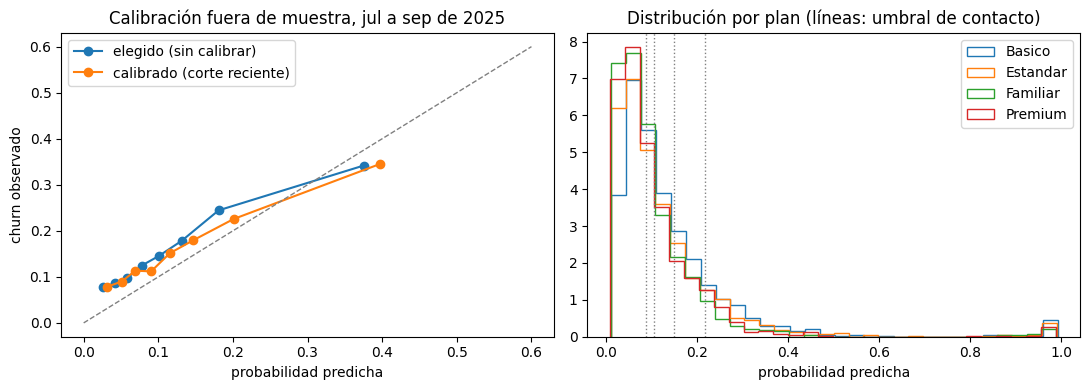

In [24]:
from sklearn.calibration import calibration_curve
from conecta.business import threshold

CHOSEN = "gbm_history_2023"
chosen = results[CHOSEN]["predictions"]
cal_p = results[f"{CHOSEN}_calibrated"]["predictions"]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for label, pr in [("elegido (sin calibrar)", chosen), ("calibrado (corte reciente)", cal_p)]:
    frac, mean_pred = calibration_curve(pr["churn_90d"], pr["p"], n_bins=8, strategy="quantile")
    ax[0].plot(mean_pred, frac, marker="o", label=label)
ax[0].plot([0, .6], [0, .6], ls="--", c="grey", lw=1)
ax[0].set(xlabel="probabilidad predicha", ylabel="churn observado", title="Calibración fuera de muestra, jul a sep de 2025")
ax[0].legend()
for plan, g in chosen.groupby("plan"):
    ax[1].hist(g["p"], bins=30, histtype="step", label=plan, density=True)
for plan in chosen["plan"].unique():
    ax[1].axvline(threshold(plan), ls=":", lw=1, c="grey")
ax[1].set(xlabel="probabilidad predicha", title="Distribución por plan (líneas: umbral de contacto)")
ax[1].legend()
plt.tight_layout()

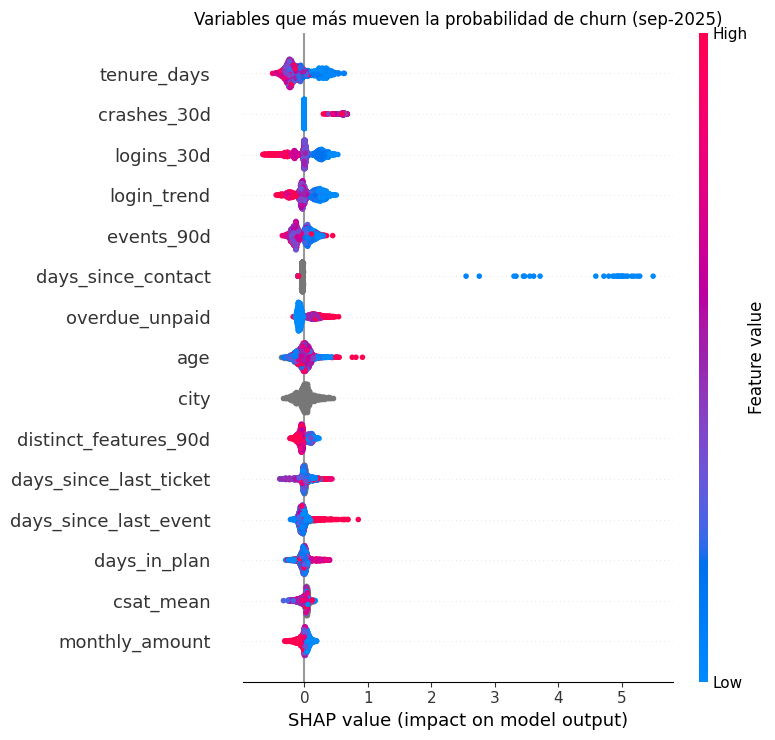

In [25]:
import shap
warnings.filterwarnings("ignore", category=UserWarning, module="shap")

train_last, ev_last = folds_2023[-1]
m_last = fit_model(panel_2023, train_last, "gbm", ALL).model
X_ev = m_last["cat"].transform(panel_2023.loc[panel_2023["cutoff"] == ev_last, ALL])
shap_values = shap.TreeExplainer(m_last["clf"]).shap_values(X_ev)
shap.summary_plot(shap_values, X_ev, max_display=15, show=False)
plt.title("Variables que más mueven la probabilidad de churn (sep-2025)")
plt.tight_layout()

Las variables que más mueven la probabilidad son la antigüedad (los clientes nuevos se van más) y el uso de la app: cierres al abrir
en los últimos 30 días, logins recientes y su tendencia. `crashes_30d` aparece segunda, y es la huella de la versión 5.2.0
(sección 8). Después vienen la facturación (vencidas sin pagar) y los tickets.

`days_since_contact` pesa porque el equipo de retención llamaba a quien ya se estaba yendo. El modelo aprende "me llamaron hace poco,
me voy", que es un efecto de selección y no de la llamada. La sección 6 lo trata.

## 6. Llamadas de retención: qué son y qué hacer con ellas

Las etiquetas reflejan la política de llamadas de entonces. Si una llamada retuvo a alguien, ese cliente quedó con etiqueta 0 aunque
se iba a ir, y el modelo aprendería que ese perfil no se va. Antes del modelo final necesito saber qué es una llamada en estos datos,
cuánto contamina las etiquetas y cómo tratarla en el modelo.

`clientes` guarda solo la última llamada de cada cliente. Juzgo cada llamada a 90 días; si fue hace menos y el cliente sigue activo,
queda censurada (todavía no se sabe), y no la cuento como retenida.

In [26]:
from conecta.retention import contact_outcomes, team_contacted

outcomes = contact_outcomes(data.clients, data.subscriptions, TODAY)
judged = outcomes[~outcomes["censored"]]
print(f"Clientes contactados: {len(outcomes):,} | censurados (llamada reciente, aún activos): {outcomes['censored'].sum()}")
print(f"Se fueron dentro de 90 días: {judged['churned_90d'].mean():.1%} | retenidos: {judged['retained'].sum()} ({judged['retained'].mean():.1%})")
d2c = outcomes["days_to_churn"].dropna()
print(f"Días entre la llamada y la baja: mediana {d2c.median():.0f}, mínimo {d2c.min():.0f}, máximo {d2c.max():.0f}")

by_year = judged.groupby(judged["contact_date"].dt.year).agg(llamadas=("retained", "size"), retenidos=("retained", "sum"),
                                                            tasa_retención=("retained", "mean"))
by_year.style.format({"tasa_retención": "{:.1%}"})

Clientes contactados: 930 | censurados (llamada reciente, aún activos): 22
Se fueron dentro de 90 días: 98.0% | retenidos: 18 (2.0%)
Días entre la llamada y la baja: mediana 11, mínimo 3, máximo 19


,llamadas,retenidos,tasa_retención
contact_date,,,
2023,71,0,0.0%
2024,268,0,0.0%
2025,569,18,3.2%


In [27]:
tk_prev = tk.merge(outcomes[["cliente_id", "contact_date"]], on="cliente_id")
day = tk_prev["created_at"].dt.normalize()
tk_prev = tk_prev[(day <= tk_prev["contact_date"]) & (day > tk_prev["contact_date"] - pd.Timedelta(days=30))]
pd.Series({
    "con cualquier ticket": tk_prev["cliente_id"].nunique() / len(outcomes),
    "con ticket de 'cancelar'": tk_prev.loc[tk_prev["topic"] == "cancelar", "cliente_id"].nunique() / len(outcomes),
    "con amenaza de irse": tk_prev.loc[tk_prev["p_threat"] > .5, "cliente_id"].nunique() / len(outcomes),
}, name="% de llamadas con … en los 30 días previos").to_frame().style.format("{:.1%}")

,% de llamadas con … en los 30 días previos
con cualquier ticket,28.3%
con ticket de 'cancelar',16.3%
con amenaza de irse,17.4%


En estos datos la llamada es un paso del proceso de baja. Toda baja posterior a una llamada ocurre entre 3 y 19 días después, y solo
~1 de cada 6 llamadas viene después de un ticket de cancelar, así que el aviso llega por otro canal, probablemente la solicitud de baja.
En 2023 y 2024 la llamada no retuvo a nadie y en 2025 retuvo a ~3 %. Con un costo de 25.000 COP, una llamada así necesita retener al
menos ~6 % para no perder plata (tabla de abajo).

In [28]:
p23 = panel_2023.copy()
contact_date = p23["cliente_id"].map(data.clients.set_index("cliente_id")["fecha_contacto_retencion"])
p23["called_in_window"] = (contact_date > p23["cutoff"]) & (contact_date <= p23["cutoff"] + pd.Timedelta(days=90))
w = p23["called_in_window"]
print(f"Filas con llamada en la ventana: {w.sum():,} ({w.mean():.1%}) | churn entre ellas: {p23.loc[w, 'churn_90d'].mean():.0%}")
print(f"Casos de churn en el panel: {p23['churn_90d'].sum():,} | de ellos en filas llamadas: {p23.loc[w, 'churn_90d'].sum():,}")
print(f"Clientes retenidos por una llamada (cota de la contaminación): {judged['retained'].sum()} "
      f"= {judged['retained'].sum() / p23['churn_90d'].sum():.1%} de los casos de churn")

Filas con llamada en la ventana: 1,963 (7.5%) | churn entre ellas: 88%
Casos de churn en el panel: 3,164 | de ellos en filas llamadas: 1,721
Clientes retenidos por una llamada (cota de la contaminación): 18 = 0.6% de los casos de churn


In [29]:
NO_CONTACT = [c for c in ALL if c not in CONTACT_FEATURES]
VARIANTS = {
    "calls_A_as_is": dict(columns=ALL, train_exclude=None),
    "calls_B_drop_called_rows": dict(columns=ALL, train_exclude=p23["called_in_window"]),
    "calls_C_no_contact_features": dict(columns=NO_CONTACT, train_exclude=None),
    "calls_D_both": dict(columns=NO_CONTACT, train_exclude=p23["called_in_window"]),
}
for name, v in VARIANTS.items():
    results[name] = evaluate_run(panel_2023, folds_2023, "gbm", v["columns"], train_exclude=v["train_exclude"])
    log_run(name, {"kind": "gbm", "n_features": len(v["columns"]), "features": v["columns"], "calibration": "none",
                   "train_from": "2023-03", "gap_months": 3, "drop_called_rows": v["train_exclude"] is not None},
            results[name])
calls = pd.DataFrame({n: {k: results[n][k] for k in ["auc", "mean_p", "realized_value", "n_contacted", "n_in_process",
                                                      "realized_value_actionable", "value_contact_all_actionable"]}
                      for n in VARIANTS}).T
calls.columns = ["AUC", "prob. media", "valor realizado", "contactos/mes", "contactos ya en proceso de baja",
                 "valor accionable", "contactar a todos (accionable)"]
m = lambda v: f"{v / 1e6:,.1f} M"
calls.style.format({"AUC": "{:.3f}", "prob. media": "{:.3f}", "valor realizado": m, "valor accionable": m,
                    "contactar a todos (accionable)": m, "contactos/mes": "{:,.0f}", "contactos ya en proceso de baja": "{:,.0f}"})

,AUC,prob. media,valor realizado,contactos/mes,contactos ya en proceso de baja,valor accionable,contactar a todos (accionable)
calls_A_as_is,0.677,0.124,13.9 M,464,27,10.3 M,4.1 M
calls_B_drop_called_rows,0.666,0.056,6.3 M,102,27,2.7 M,4.1 M
calls_C_no_contact_features,0.668,0.120,13.7 M,491,20,10.7 M,4.1 M
calls_D_both,0.659,0.055,5.5 M,123,13,3.6 M,4.1 M


"En proceso de baja" significa que el equipo lo llamó en los últimos 30 días o que tiene un ticket de cancelar en los últimos 90
(`in_cancellation_process` en `conecta/business.py`). El valor accionable excluye a esos clientes de la lista. La tabla siguiente
muestra cuántos de ellos se van y qué probabilidad les da el modelo.

In [30]:
from conecta.business import PROCESS_WINDOW_DAYS, in_cancellation_process
key = ["cliente_id", "cutoff"]
called = p23["days_since_contact"].le(PROCESS_WINDOW_DAYS)
cancel = p23["topic_cancelar_90d"].gt(0)
bt = results["calls_C_no_contact_features"]["predictions"].merge(p23[key].assign(called=called, cancel=cancel), on=key)

def process_row(in_panel, in_bt):
    return {"filas (todos los cortes)": int(in_panel.sum()), "churn real": p23.loc[in_panel, "churn_90d"].mean(),
            "filas (backtest jul a sep)": int(in_bt.sum()), "churn real (backtest)": bt.loc[in_bt, "churn_90d"].mean(),
            "prob. media del modelo (backtest)": bt.loc[in_bt, "p"].mean()}

in_process_all = in_cancellation_process(p23)
process_tbl = pd.DataFrame({
    "llamado por el equipo en los últimos 30 días": process_row(called, bt["called"]),
    "ticket de cancelar en los últimos 90 días": process_row(cancel, bt["cancel"]),
    "en proceso de baja (cualquiera de los dos)": process_row(in_process_all, bt["in_process"]),
    "resto de los clientes": process_row(~in_process_all, ~bt["in_process"]),
}).T
process_tbl.style.format({"filas (todos los cortes)": "{:,.0f}", "filas (backtest jul a sep)": "{:,.0f}", "churn real": "{:.0%}",
                          "churn real (backtest)": "{:.0%}", "prob. media del modelo (backtest)": "{:.0%}"})

,filas (todos los cortes),churn real,filas (backtest jul a sep),churn real (backtest),prob. media del modelo (backtest)
llamado por el equipo en los últimos 30 días,249,95%,70,91%,38%
ticket de cancelar en los últimos 90 días,112,100%,29,100%,93%
en proceso de baja (cualquiera de los dos),302,96%,81,93%,45%
resto de los clientes,"26,006",11%,"4,994",15%,12%


Los clientes en proceso de baja se van casi todos: 96 % en el panel y 93 % en los meses del backtest. El modelo lo reconoce
cuando hay un ticket de cancelar, que es una variable que sí ve (probabilidad media de 93 %). No lo reconoce cuando la única señal
es la llamada del equipo (38 % contra 91 % real), porque el modelo final no usa las variables de contacto (punto 2 de abajo).

Por eso la `probabilidad` de `predicciones.csv` queda por debajo del riesgo real para estos clientes. No la reemplazo por la tasa
histórica: el archivo entrega la salida del modelo, y la decisión de no contactarlos no depende de esa probabilidad.

Decisión:
1. No se corrigen las etiquetas. La contaminación es menor al 1 % de los casos de churn, y la corrección por exclusión (B) hace daño:
   como las llamadas siguen al churn, quitar las filas llamadas borra más de la mitad de los positivos, la probabilidad se desploma y el
   valor cae a la mitad.
2. El modelo final no usa `contacted_before` ni `days_since_contact` (C). Vale prácticamente lo mismo y no depende de la política
   actual. Si el equipo cambia su forma de llamar, o este modelo la reemplaza, esas variables cambian de significado.
3. No recomiendo contactar a quien ya está en proceso de baja. Lo atiende el flujo actual y casi todos se van igual (tabla de
   arriba), así que suponer que la llamada lo retiene al 40 % no tiene sustento. Por eso reporto el valor accionable y no el de la regla pura.

In [31]:
from conecta.business import break_even_effectiveness, realized_value
FINAL_COLUMNS = NO_CONTACT
pred = results["calls_C_no_contact_features"]["predictions"]
rows = []
for ev, g in pred.groupby("cutoff"):
    team = team_contacted(data.clients, ev, g["cliente_id"]).to_numpy()
    top100 = (g["p"].where(~g["in_process"]).rank(ascending=False, method="first") <= 100).to_numpy()
    for name, sel in [("equipo hoy (llamadas del mes siguiente)", team),
                      ("modelo: regla, sin los ya en proceso", g["contact_actionable"].to_numpy().astype(bool)),
                      ("modelo: top 100, sin los ya en proceso", top100)]:
        rows.append({"mes": f"{ev:%Y-%m}", "estrategia": name, "llamadas": int(sel.sum()),
                     "% que se iba": g.loc[sel, "churn_90d"].mean(),
                     "gasto (M)": sel.sum() * 25_000 / 1e6,
                     **{f"neto si retiene {int(e * 100)} % (M)": realized_value(sel, g["churn_90d"], g["plan"], effectiveness=e) / 1e6
                        for e in (0.4, 0.2, 0.1, 0.03)},
                     "efectividad de equilibrio": break_even_effectiveness(sel, g["churn_90d"], g["plan"])})
vs_team = pd.DataFrame(rows).groupby("estrategia", sort=False).mean(numeric_only=True)
vs_team.style.format({c: ("{:.0f}" if c == "llamadas" else "{:.0%}" if c in ("% que se iba", "efectividad de equilibrio")
                         else "{:.1f}") for c in vs_team.columns})

,llamadas,% que se iba,gasto (M),neto si retiene 40 % (M),neto si retiene 20 % (M),neto si retiene 10 % (M),neto si retiene 3 % (M),efectividad de equilibrio
estrategia,,,,,,,,
equipo hoy (llamadas del mes siguiente),58,98%,1.5,8.8,3.7,1.1,-0.7,6%
"modelo: regla, sin los ya en proceso",472,23%,11.8,10.7,-0.5,-6.2,-10.1,21%
"modelo: top 100, sin los ya en proceso",100,30%,2.5,2.3,-0.1,-1.3,-2.1,21%


In [32]:
top_rows = []
for ev, g in pred.groupby("cutoff"):
    top = g[~g["in_process"]].nlargest(100, "p")
    top_rows.append({"mes": f"{ev:%Y-%m}", "churn de los 100 de mayor riesgo": top["churn_90d"].mean(),
                     "churn de todos los clientes": g["churn_90d"].mean()})
top_tbl = pd.DataFrame(top_rows).set_index("mes")
top_tbl["veces el promedio"] = top_tbl["churn de los 100 de mayor riesgo"] / top_tbl["churn de todos los clientes"]
top_tbl.style.format({"churn de los 100 de mayor riesgo": "{:.0%}", "churn de todos los clientes": "{:.0%}", "veces el promedio": "{:.1f}"})

,churn de los 100 de mayor riesgo,churn de todos los clientes,veces el promedio
mes,,,
2025-07,24%,15%,1.6
2025-08,31%,17%,1.8
2025-09,36%,16%,2.2


Lectura para la gerencia:
- El equipo apunta mejor que el modelo, porque casi todos los que llama se iban. Lo logra llamando cuando la baja ya está en curso.
  Esas llamadas retienen ~3 % (columna "neto si retiene 3 %"), por debajo del ~6 % que necesitan: hoy se gasta poco y se pierde un poco.
- El modelo llama con meses de anticipación, a más gente y con menos certeza: se iba entre 1 de cada 4 y 3 de cada 10 contactados.
  Necesita que la llamada temprana retenga al menos ~21 %. Si retiene el 40 % del enunciado, gana ~10 M COP al mes; si retiene 10 %,
  pierde. Los datos no dicen cuál de los dos casos ocurre, porque nunca se llamó temprano.
- Recomiendo un piloto con grupo de control antes de reemplazar al equipo: de los 100 clientes de mayor riesgo fuera del flujo de baja,
  llamar a la mitad y comparar con la otra mitad durante 2 o 3 meses. Son 50 llamadas al mes, unos 1,25 M COP, algo menos de lo que
  gasta hoy el equipo (~1,5 M), y mide la efectividad real.
  Si supera el punto de equilibrio (~21 %), se escala.

### 6.1 Confirmación en meses que no usé para decidir: abril a junio de 2025

Todas las decisiones de las secciones 5 y 6 se tomaron mirando julio, agosto y septiembre. Para ver si se sostienen, repito las
comparaciones en abril, mayo y junio de 2025, que no usé para ninguna. La separación es de 4 meses, porque un fin de enero más 90 días
cae en mayo y la etiqueta de enero aún no se conocía el 30 de abril.

Comparo las dos decisiones que estos meses pueden juzgar: calibrar o no, y usar o no las variables de contacto. La decisión de usar el
historial desde 2023 no se puede juzgar aquí: con 4 meses de separación, el panel de 2025 casi no tiene cortes para entrenar en esos
meses, así que la comparación saldría a favor del historial de antemano.

In [33]:
HOLDOUT_CUTOFFS = [pd.Timestamp(c) for c in ["2025-04-30", "2025-05-31", "2025-06-30"]]
folds_holdout = temporal_folds(sorted(panel_2023["cutoff"].unique()), HOLDOUT_CUTOFFS, gap_months=4)
HOLDOUT_RUNS = {
    "base (regresión logística)": dict(kind="base", columns=BASE_FEATURES),
    "con contacto, sin calibrar": dict(kind="gbm", columns=ALL),
    "con contacto, calibrado": dict(kind="gbm", columns=ALL, calibration="recent"),
    "sin contacto, calibrado": dict(kind="gbm", columns=NO_CONTACT, calibration="recent"),
    "sin contacto, sin calibrar (elegido)": dict(kind="gbm", columns=NO_CONTACT),
}
holdout = {name: evaluate_run(panel_2023, folds_holdout, **v) for name, v in HOLDOUT_RUNS.items()}
holdout_tbl = pd.DataFrame({n: {k: r[k] for k in ["auc", "mean_p", "churn_rate", "realized_value", "realized_value_actionable",
                                                   "value_contact_all_actionable", "n_contacted_actionable"]}
                            for n, r in holdout.items()}).T
holdout_tbl.columns = ["AUC", "prob. media", "churn real", "valor realizado", "valor accionable", "contactar a todos (accionable)",
                       "contactos/mes (accionable)"]
display(holdout_tbl.style.format({"AUC": "{:.3f}", "prob. media": "{:.3f}", "churn real": "{:.3f}", "valor realizado": m,
                                  "valor accionable": m, "contactar a todos (accionable)": m,
                                  "contactos/mes (accionable)": "{:,.0f}"}))

by_month = pd.DataFrame({n: r["per_fold"].set_index("cutoff")["realized_value_actionable"] / 1e6 for n, r in holdout.items()})
by_month.index = by_month.index.strftime("%Y-%m")
display(by_month.style.format("{:.1f} M"))

chosen_name = "sin contacto, sin calibrar (elegido)"
wins = {n: f"{(by_month[chosen_name] > by_month[n]).sum()} de {len(by_month)}" for n in by_month if n != chosen_name}
print("Meses en que el elegido supera a cada alternativa (valor accionable):", wins)

,AUC,prob. media,churn real,valor realizado,valor accionable,contactar a todos (accionable),contactos/mes (accionable)
base (regresión logística),0.569,0.096,0.118,0.6 M,-0.5 M,-9.3 M,320
"con contacto, sin calibrar",0.615,0.097,0.118,3.8 M,1.3 M,-9.3 M,259
"con contacto, calibrado",0.615,0.118,0.118,3.6 M,1.2 M,-9.3 M,382
"sin contacto, calibrado",0.600,0.115,0.118,2.9 M,1.1 M,-9.3 M,393
"sin contacto, sin calibrar (elegido)",0.600,0.094,0.118,2.7 M,1.1 M,-9.3 M,274


,base (regresión logística),"con contacto, sin calibrar","con contacto, calibrado","sin contacto, calibrado","sin contacto, sin calibrar (elegido)"
cutoff,,,,,
2025-04,-1.2 M,0.0 M,-0.5 M,-1.2 M,-1.2 M
2025-05,-1.0 M,1.1 M,1.0 M,1.0 M,1.2 M
2025-06,0.8 M,2.8 M,3.1 M,3.6 M,3.1 M


Meses en que el elegido supera a cada alternativa (valor accionable): {'base (regresión logística)': '3 de 3', 'con contacto, sin calibrar': '2 de 3', 'con contacto, calibrado': '2 de 3', 'sin contacto, calibrado': '2 de 3'}


Resultado:
- Las dos decisiones se sostienen, sin ganar por mucho. Calibrar no cambia el valor accionable: 1,2 M contra 1,3 M con variables de
  contacto, y 1,1 M en ambos casos sin ellas. Quitar las variables de contacto cuesta ~0,2 M al mes, dentro de la variación entre
  meses, igual que en julio a septiembre. El LightGBM supera a la regresión base en los tres meses.
- El valor es mucho menor que en julio a septiembre: ~1 M al mes contra ~10,7 M accionable. El churn de estos meses es más bajo (12 %
  contra ~16 %), al punto de que contactar a todos pierde 9,3 M al mes. Además, con 4 meses de separación el modelo de abril entrena
  sin ningún mes con logs de la app y el de mayo con uno solo, así que casi no aprende la señal de uso (AUC ~0,60 contra ~0,67).
- El valor del modelo depende del nivel de churn y de tener logs en el entrenamiento. Con churn bajo, la lista apenas cubre su costo
  aun con el 40 % del enunciado, y eso refuerza hacer el piloto antes de escalar.

## 7. Decisión de contacto: a quién llamar en enero de 2026

Modelo final: LightGBM con parámetros fijos, entrenado con todos los cortes de marzo de 2023 a septiembre de 2025, sin las variables de
contacto (sección 6) y sin recalibrar (sección 5). La última etiqueta disponible es la del 30-sep, que se conoce el 29-dic. Entre ese
corte y el puntaje del 31-dic hay los mismos 3 meses que en el backtest, así que el desempeño medido es el que cabe esperar.

Regla: contactar si `p · 0,40 · 12 · precio > 25.000`, con umbral por plan, salvo que el cliente ya esté en proceso de baja (llamada
del equipo en los últimos 30 días o ticket de cancelar en los últimos 90). A ese cliente lo atiende el flujo actual.

In [34]:
from conecta.business import (PRICES, decide_contact, expected_value, in_cancellation_process, sensitivity, threshold)
from conecta.models import validate_predictions

final_cutoffs = sorted(panel_2023["cutoff"].unique())
final_model = fit_model(panel_2023, final_cutoffs, "gbm", FINAL_COLUMNS)
log_run("final_gbm_history_2023_no_contact",
        {"kind": "gbm", "n_features": len(FINAL_COLUMNS), "features": FINAL_COLUMNS, "calibration": "none",
         "train_from": "2023-03", "train_to": f"{final_cutoffs[-1]:%Y-%m}", "gap_months": 3,
         "note": "métricas = backtest de calls_C_no_contact_features; modelo = reentrenado con todos los cortes"},
        results["calls_C_no_contact_features"], model=final_model.model)

scored = X_score.copy()
scored["probabilidad"] = final_model.predict_proba(X_score[FINAL_COLUMNS])[:, 1]
scored["in_process"] = in_cancellation_process(X_score)
scored["rule"] = decide_contact(scored["probabilidad"], scored["plan"])
scored["contactar"] = (scored["rule"].astype(bool) & ~scored["in_process"]).astype(int)
scored["expected_value"] = expected_value(scored["probabilidad"], scored["plan"])

predictions = scored.reset_index()[["cliente_id", "probabilidad", "contactar"]].round({"probabilidad": 6})
validate_predictions(predictions, set(data.to_score["cliente_id"]))
predictions.to_csv("predicciones.csv", index=False)

contact = scored["contactar"] == 1
print(f"predicciones.csv: {len(predictions):,} clientes | contactar: {contact.sum():,} ({contact.mean():.0%})")
print(f"Valor esperado de la lista (con los supuestos del enunciado): {scored.loc[contact, 'expected_value'].sum() / 1e6:,.1f} M COP")
print(f"Probabilidad media: {scored['probabilidad'].mean():.1%} (churn de los últimos cortes conocidos: "
      f"{panel.loc[panel['cutoff'] >= '2025-07-31', 'churn_90d'].mean():.1%})")

predicciones.csv: 1,556 clientes | contactar: 634 (41%)
Valor esperado de la lista (con los supuestos del enunciado): 15.9 M COP
Probabilidad media: 16.1% (churn de los últimos cortes conocidos: 16.2%)


In [35]:
def by(col):
    g = scored.groupby(col, observed=True)
    out = pd.DataFrame({"clientes": g.size(), "contactar": g["contactar"].sum(), "% contactar": g["contactar"].mean(),
                        "prob. media": g["probabilidad"].mean(),
                        "valor esperado (M)": scored.loc[contact].groupby(col, observed=True)["expected_value"].sum() / 1e6})
    return out.fillna(0)
plan_tbl = by("plan")
plan_tbl.insert(0, "umbral", [threshold(p) for p in plan_tbl.index])
fmt = {"umbral": "{:.1%}", "% contactar": "{:.0%}", "prob. media": "{:.1%}", "valor esperado (M)": "{:.1f}"}
display(plan_tbl.style.format(fmt))
display(by("segment").style.format(fmt))

,umbral,clientes,contactar,% contactar,prob. media,valor esperado (M)
plan,,,,,,
Basico,21.8%,504,143,28%,17.5%,2.1
Estandar,14.9%,475,195,41%,16.5%,4.1
Familiar,8.7%,251,141,56%,14.9%,5.0
Premium,10.4%,326,155,48%,14.2%,4.7


,clientes,contactar,% contactar,prob. media,valor esperado (M)
segment,,,,,
Personal,1229,515,42%,16.8%,12.9
Pyme,327,119,36%,13.5%,3.0


In [36]:
eligible = ~scored["in_process"]
sens = sensitivity(scored.loc[eligible, "probabilidad"], scored.loc[eligible, "plan"], effectivenesses=(0.1, 0.2, 0.4, 0.6))
sens.columns = ["efectividad", "clientes a contactar", "valor esperado total (M)"]
sens["valor esperado total (M)"] /= 1e6
sens.style.format({"efectividad": "{:.0%}", "valor esperado total (M)": "{:.1f}"}).hide(axis="index")

efectividad,clientes a contactar,valor esperado total (M)
10%,32,0.1
20%,237,2.9
40%,634,15.9
60%,919,33.3


In [37]:
ip = scored["in_process"]
print(f"En proceso de baja al 31-dic: {ip.sum()} clientes | la regla pura los contactaría a {scored.loc[ip, 'rule'].sum()} "
      f"| probabilidad media {scored.loc[ip, 'probabilidad'].mean():.0%}")

En proceso de baja al 31-dic: 18 clientes | la regla pura los contactaría a 13 | probabilidad media 40%


Todas las corridas registradas en MLflow, incluidas las variantes de llamadas y el modelo final:

In [38]:
runs = mlflow.search_runs(experiment_names=[EXPERIMENT], order_by=["metrics.realized_value DESC"])
runs[list(cols_show)].rename(columns=cols_show).style.format(
    {"AUC-PR": "{:.3f}", "AUC": "{:.3f}", "Brier": "{:.3f}", "contactados/mes": "{:,.0f}", **money}).hide(axis="index")

corrida,calibración,AUC-PR,AUC,Brier,valor realizado,desv. entre folds,contactar a todos,oráculo,contactados/mes
calls_A_as_is,none,0.358,0.677,0.124,13.9 M,6.0 M,7.8 M,43.2 M,464
gbm_history_2023,none,0.358,0.677,0.124,13.9 M,6.0 M,7.8 M,43.2 M,464
gbm_history_2023_calibrated,recent,0.358,0.677,0.124,13.9 M,6.6 M,7.8 M,43.2 M,561
final_gbm_history_2023_no_contact,none,0.308,0.668,0.129,13.7 M,6.0 M,7.8 M,43.2 M,491
calls_C_no_contact_features,none,0.308,0.668,0.129,13.7 M,6.0 M,7.8 M,43.2 M,491
gbm_full_calibrated,recent,0.344,0.665,0.126,13.6 M,5.6 M,7.8 M,43.2 M,558
gbm_full,none,0.344,0.665,0.126,13.1 M,6.0 M,7.8 M,43.2 M,427
calls_B_drop_called_rows,none,0.350,0.666,0.134,6.3 M,3.0 M,7.8 M,43.2 M,102
gbm_no_unstructured,none,0.275,0.578,0.133,6.0 M,3.5 M,7.8 M,43.2 M,329
base,none,0.195,0.558,0.137,5.9 M,3.8 M,7.8 M,43.2 M,269


Lectura:
- La lista responde al enunciado tal como está planteado: si la llamada retiene al 40 %, contactar a cada uno de estos clientes tiene
  valor esperado positivo. El modelo final ya vio los meses de churn alto y su probabilidad media coincide con el churn reciente. En el
  backtest, los modelos que no habían visto esos meses quedaban por debajo.
- Los 18 clientes en proceso de baja tienen una probabilidad media de 40 %, aunque ese grupo se va casi entero (sección 6). No se
  contactan, y su probabilidad es la del modelo sin ajustes.
- Se contacta más en los planes caros, que tienen umbral más bajo: retener a un cliente Familiar vale 2,5 veces lo que retener a uno Básico.
- Las llamadas cuestan ~16 M COP (634 × 25.000) y el valor esperado neto es de ~16 M, así que el retorno depende del 40 %.
- El 40 % es el supuesto que más pesa (tabla de sensibilidad). Con 10 % casi nadie justifica la llamada, y las llamadas actuales, hechas
  tarde, retienen ~3 %. Antes de llamar a toda la lista conviene medir la efectividad con el piloto de la sección 6.

## 8. Hallazgos: por qué se van los clientes

Tres hallazgos, ordenados por impacto, cada uno con su evidencia, sus salvedades y la acción que propongo.

In [39]:
BLUE, ORANGE, AQUA, GREY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#a3a29c", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e6e5e0",
                     "grid.linewidth": .8, "axes.axisbelow": True, "axes.edgecolor": GREY, "axes.labelcolor": INK,
                     "xtick.color": INK, "ytick.color": INK, "axes.titleweight": "bold", "axes.titlesize": 11})

def bar_labels(ax, bars, fmt):
    for b in bars:
        ax.annotate(fmt(b.get_height()), (b.get_x() + b.get_width() / 2, b.get_height()), ha="center", va="bottom",
                    fontsize=9, color=INK, xytext=(0, 2), textcoords="offset points")

### 8.1 La versión 5.2.0 de la app (solo Android) está echando clientes

Errores CRASH_ON_START: {'5.1.3': 169, '5.2.0': 7926, 'web': 28}
Plataformas con 5.2.0: ['android'] | primera fecha: 2025-09-01
{'Android con 5.2.0': '595 clientes, churn 28.2%', 'Android sin 5.2.0': '370 clientes, churn 11.1%', 'iOS': '581 clientes, churn 8.4%', 'Web': '188 clientes, churn 13.3%'}
2025-06-30 {'android': 0.155, 'ios': 0.11, 'web': 0.097}
2025-09-30 {'android': 0.217, 'ios': 0.084, 'web': 0.133}
Tickets 'la app se cierra' antes de sep-2025: 0 | desde sep: 816
Hoy (31-dic): 464 clientes activos usan la 5.2.0 | prob. media 28% vs 11% | son 381 de los 634 a contactar
Exceso de churn: 17% → ~80 bajas de más en un trimestre, que equivalen a ~36 M COP en 12 meses de mensualidades de esos clientes


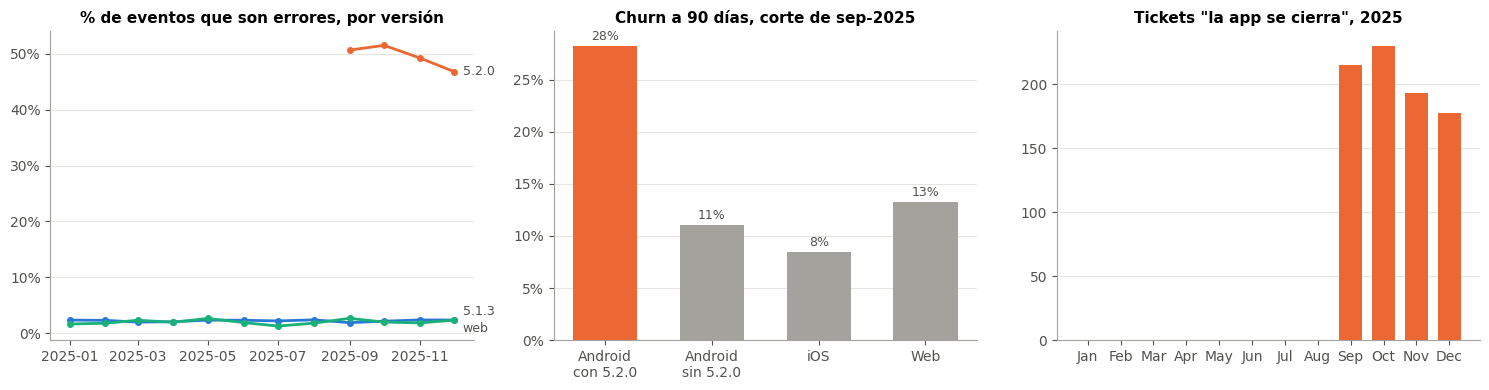

In [40]:
ev = data.events.assign(month=data.events["local_date"].dt.to_period("M"))
err = ev.pivot_table(index="month", columns="version_app", values="tipo", aggfunc=lambda s: (s == "error_app").mean())
sep = panel[panel["cutoff"] == "2025-09-30"]
android_app = set(ev.loc[(ev["plataforma"] == "android") & (ev["local_date"] > "2025-07-02"), "cliente_id"])
groups = {
    "Android\ncon 5.2.0": sep[sep["uses_v520"] == 1],
    "Android\nsin 5.2.0": sep[(sep["uses_v520"] == 0) & sep["cliente_id"].isin(android_app)],
    "iOS": sep[sep["main_platform"] == "ios"],
    "Web": sep[sep["main_platform"] == "web"],
}
crash_tk = tk[tk["topic"] == "app_se_cierra"].groupby(tk["created_at"].dt.to_period("M")).size()
crash_tk = crash_tk.reindex(pd.period_range("2025-01", "2025-12", freq="M"), fill_value=0)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for col, color, dy in [("5.1.3", BLUE, 6), ("web", AQUA, -6), ("5.2.0", ORANGE, 0)]:
    s = err[col].dropna()
    ax[0].plot(s.index.to_timestamp(), s.values, color=color, lw=2, marker="o", ms=4)
    ax[0].annotate(col, (s.index[-1].to_timestamp(), s.values[-1]), xytext=(6, dy), textcoords="offset points",
                   va="center", color=INK, fontsize=9)
ax[0].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax[0].set(title="% de eventos que son errores, por versión", ylabel="")
rates = {k: g["churn_90d"].mean() for k, g in groups.items()}
bars = ax[1].bar(rates.keys(), rates.values(), color=[ORANGE, GREY, GREY, GREY], width=.6)
bar_labels(ax[1], bars, lambda v: f"{v:.0%}")
ax[1].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax[1].set(title="Churn a 90 días, corte de sep-2025")
bars = ax[2].bar(crash_tk.index.strftime("%b"), crash_tk.values,
                 color=[ORANGE if m >= pd.Period("2025-09") else GREY for m in crash_tk.index], width=.7)
ax[2].set(title='Tickets "la app se cierra", 2025')
plt.tight_layout()

print("Errores CRASH_ON_START:", ev[ev["codigo_error"] == "CRASH_ON_START"].groupby("version_app").size().to_dict())
print("Plataformas con 5.2.0:", ev.loc[ev["version_app"] == "5.2.0", "plataforma"].unique().tolist(),
      "| primera fecha:", ev.loc[ev["version_app"] == "5.2.0", "local_date"].min().date())
print({k.replace(chr(10), " "): f"{len(g)} clientes, churn {g['churn_90d'].mean():.1%}" for k, g in groups.items()})
for c in ["2025-06-30", "2025-09-30"]:
    print(c, panel[panel["cutoff"] == c].groupby("main_platform")["churn_90d"].mean().round(3).to_dict())
print(f"Tickets 'la app se cierra' antes de sep-2025: {crash_tk[:8].sum()} | desde sep: {crash_tk[8:].sum()}")
v520_now = X_score["uses_v520"] == 1
print(f"Hoy (31-dic): {v520_now.sum()} clientes activos usan la 5.2.0 | prob. media {scored.loc[v520_now, 'probabilidad'].mean():.0%} "
      f"vs {scored.loc[~v520_now, 'probabilidad'].mean():.0%} | son {scored.loc[v520_now, 'contactar'].sum()} de los "
      f"{scored['contactar'].sum()} a contactar")
excess = rates["Android\ncon 5.2.0"] - rates["Android\nsin 5.2.0"]
at_risk = X_score.loc[v520_now, "plan"].map(PRICES).sum() * 12 * excess
print(f"Exceso de churn: {excess:.0%} → ~{excess * v520_now.sum():.0f} bajas de más en un trimestre, "
      f"que equivalen a ~{at_risk / 1e6:.0f} M COP en 12 meses de mensualidades de esos clientes")

Evidencia: la 5.2.0 salió el 1-sep-2025, solo en Android. La mitad de sus eventos son errores `CRASH_ON_START` (la app se cierra al
abrir), contra ~2 % de errores en la 5.1.3 y en la web. En el corte de septiembre, quienes la usan tienen 28 % de churn a 90 días y
los usuarios de Android que siguen en la 5.1.3 tienen 11 %. La comparación es dentro de la misma plataforma, así que la diferencia
no viene de que Android ya fuera peor. El churn de Android pasa de 16 % a 22 % entre junio y septiembre, mientras el de iOS baja de
11 % a 8 %. Todos los tickets de "la app se cierra" del año llegaron desde septiembre. Hoy usan la 5.2.0 unos 460 clientes activos,
cerca del 60 % de la lista de contacto.

Salvedades: es un estudio observacional y quienes actualizan rápido podrían diferir de quienes no. Pero el salto coincide en fecha,
plataforma y tipo de error, y ningún otro dato sugiere otra explicación.

Acción: retirar la 5.2.0 de la tienda o publicar un arreglo urgente, y avisar a los afectados. Sale más barato que llamarlos y ataca
la causa de la mayoría de la lista de contacto. El seguimiento se hace con la tasa de `CRASH_ON_START` y el churn de Android.

### 8.2 Hay cobros dobles reales, y cada vez más

Clientes con ticket de cobro doble: 622 | con una factura duplicada real: 100%
Clientes con factura duplicada: 622 | que se quejaron: 100%
Tickets de cobro doble evaluables: 516 | irónicos: 137


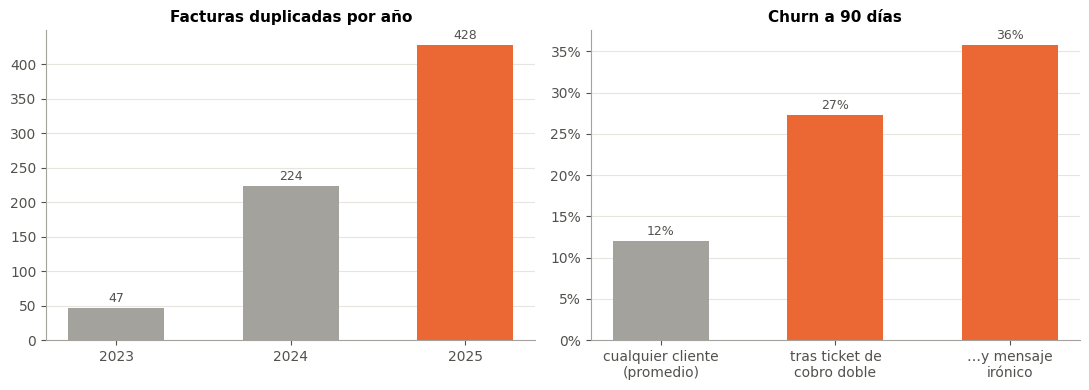

In [41]:
dup = data.invoices[data.invoices["is_duplicate_charge"]]
dup_year = dup.groupby(dup["fecha_carga"].dt.year).size()
dbl_clients = tk.loc[tk["topic"] == "cobro_doble", "cliente_id"].unique()
dup_clients = dup["cliente_id"].unique()
print(f"Clientes con ticket de cobro doble: {len(dbl_clients)} | con una factura duplicada real: {np.isin(dbl_clients, dup_clients).mean():.0%}")
print(f"Clientes con factura duplicada: {len(dup_clients)} | que se quejaron: {np.isin(dup_clients, dbl_clients).mean():.0%}")

subs_by_client = dict(tuple(data.subscriptions.groupby("cliente_id")))
t = tk[(tk["topic"] == "cobro_doble") & (tk["created_at"] <= "2025-09-30")].copy()
t["day"] = t["created_at"].dt.normalize()
t = t[[c in active_at(subs_by_client[c], d) for c, d in zip(t["cliente_id"], t["day"])]]
t["churn"] = [int(c not in active_at(subs_by_client[c], d + pd.Timedelta(days=90))) for c, d in zip(t["cliente_id"], t["day"])]
base_rate = panel_2023["churn_90d"].mean()

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
bars = ax[0].bar(dup_year.index.astype(str), dup_year.values, color=[GREY, GREY, ORANGE], width=.55)
bar_labels(ax[0], bars, lambda v: f"{v:.0f}")
ax[0].set(title="Facturas duplicadas por año")
churn_tbl = {"cualquier cliente\n(promedio)": base_rate, "tras ticket de\ncobro doble": t["churn"].mean(),
             "…y mensaje\nirónico": t.loc[t["p_irony"] > .5, "churn"].mean()}
bars = ax[1].bar(churn_tbl.keys(), churn_tbl.values(), color=[GREY, ORANGE, ORANGE], width=.55)
bar_labels(ax[1], bars, lambda v: f"{v:.0%}")
ax[1].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax[1].set(title="Churn a 90 días")
plt.tight_layout()
print(f"Tickets de cobro doble evaluables: {len(t)} | irónicos: {(t['p_irony'] > .5).sum()}")

Evidencia: todos los clientes que reclamaron un cobro doble tienen una factura duplicada, con otro número, en el mismo periodo, y
todos los clientes con una factura duplicada reclamaron. Los duplicados crecen: 47 en 2023, 224 en 2024 y 428 en 2025. Tomando los
reclamos hasta el 30-sep-2025 de clientes activos, 1 de cada 4 se va en los 90 días siguientes, el doble del promedio, y más de 1 de
cada 3 si el reclamo es irónico, por ejemplo cuando el cliente celebra que le cobren dos veces. Ese tono solo aparece en el texto; la categoría del ticket no lo tiene.

Salvedades: no se sabe si el cobro se reembolsó ni cuándo. Con ese dato se podría medir si reembolsar rápido reduce el churn.

Acción: corregir el proceso que genera la factura duplicada, que es sistemático y va en aumento. Mientras tanto, detectar el duplicado
al cargarlo y reembolsar antes de que el cliente lo note.

### 8.3 La retención llega tarde

Llamadas evaluables: 908 | se fueron igual: 98% | mediana de días hasta la baja: 11


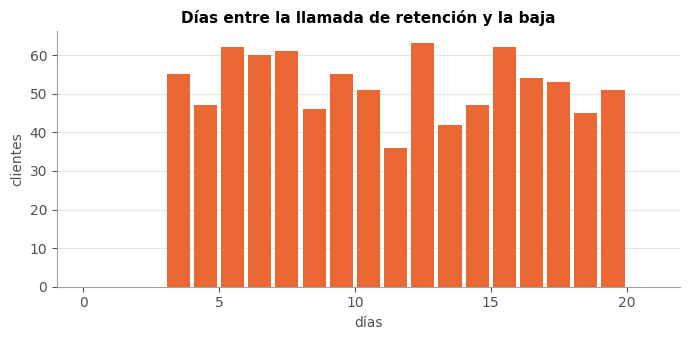

In [42]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(outcomes["days_to_churn"].dropna(), bins=range(0, 22), color=ORANGE, rwidth=.85)
ax.set(title="Días entre la llamada de retención y la baja", xlabel="días", ylabel="clientes")
plt.tight_layout()
print(f"Llamadas evaluables: {len(judged)} | se fueron igual: {judged['churned_90d'].mean():.0%} | "
      f"mediana de días hasta la baja: {outcomes['days_to_churn'].median():.0f}")

Evidencia (sección 6): el equipo llama a 6 de cada 10 clientes que se van, siempre en sus últimas tres semanas, y el 98 % se va igual.
En 2023 y 2024 no retuvo a nadie; en 2025 retuvo a ~3 %, la mitad de lo necesario para cubrir el costo de la llamada.

Salvedades: el 98 % está sesgado porque se llamó a quien ya se iba. Muestra que la oferta llega cuando la decisión está tomada, no que
la oferta sea mala. Tampoco se sabe qué pasaría con una llamada temprana, porque nunca se hizo.

Acción: llamar antes, con la lista del modelo, que avisa con hasta 90 días, y medirlo con un grupo de control. De los 100 clientes de
mayor riesgo, se llama a 50 y se compara con los otros 50 durante 2 o 3 meses. Cuesta unos 1,25 M COP al mes, algo menos de lo que
gasta hoy el equipo.

## 9. Cómo llevarlo a producción

Operación: el día 1 de cada mes se arma la matriz con lo cargado hasta el último día del mes anterior (`build_matrix`, con las facturas
filtradas por `fecha_carga` igual que en el entrenamiento), se puntúa y se entrega la lista con su valor esperado. Propongo reentrenar
cada mes: cuesta segundos, y en el backtest los modelos que no habían visto los meses recientes subestimaban el churn, mientras la probabilidad
media del modelo final, entrenado hasta septiembre, coincide con el churn reciente. La etiqueta más reciente utilizable es la de hace 3 meses. Las pruebas de `tests/`
corren antes de cada entrega.

Qué vigilar cada mes, con alarma:
- Churn real frente al predicho, por plan y plataforma, y valor realizado frente al esperado, a medida que cierra cada ventana de 90 días.
- Cambios bruscos en las variables que más pesan (logins, cierres de la app, vencidas sin pagar), la cobertura diaria de logs y
  tickets, el retraso de `fecha_carga` y el porcentaje de tickets con texto nuevo sin clasificar (`unclassified_tickets_90d`). Si ese
  porcentaje supera ~10 %, se corre de nuevo la clasificación con `RECALCULATE_NLP = True`.
- Facturas duplicadas por mes y tasa de `CRASH_ON_START` por versión, que sirven a la vez como alarma del modelo y como indicador de negocio.

Una nueva versión de la app, un cambio de precios o un cambio en la política de llamadas alteran el comportamiento de los clientes, y el
modelo tarda al menos un mes en verlo. Por eso las variables de contacto ya no entran al modelo (sección 6). La recalibración se retoma
cuando haya varios meses con el nuevo nivel de churn.

Las cifras del backtest están algo infladas, porque las decisiones de modelado se tomaron mirando los mismos tres meses de
evaluación. La sección 6.1 confirma dos de ellas (sin calibrar, sin variables de contacto) en abril a junio, donde el valor fue mucho
menor. El historial desde 2023 y la ventana de 30 días del proceso de baja no tienen esa confirmación. Los primeros meses de operación,
con el grupo de control, la darán.

Cada lista lleva un grupo de control aleatorio; por ejemplo, 50 de los 100 de mayor riesgo no se llaman. Así el 40 % del enunciado se
reemplaza por la efectividad medida, y los umbrales se recalculan con ella.